In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import regionmask
import xarray as xr
from matplotlib.gridspec import GridSpec
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

from fast_o3_iv import utils
from fast_o3_iv.config import INTERIM_DATA_DIR
from fast_o3_iv.modeling.train import DatasetConfig
import fast_o3_iv.bias_correction as bc

In [5]:
def make_config(source_id, experiment, start, stop):
    return DatasetConfig(
        source_id=source_id,
        cmip_experiment_id=experiment,
        variable_setname="setC",
        year_range=range(start, stop),
    )

config_hist_original   = make_config("CESM2-WACCM6", "historical", 1975, 2015)
config_hist_synthetic  = make_config("CESM2",        "historical", 1975, 2015)

config_ssp245_original  = make_config("CESM2-WACCM6", "ssp245", 2015, 2055)
config_ssp245_synthetic = make_config("CESM2",        "ssp245", 2015, 2055)

config_ssp585_original  = make_config("CESM2-WACCM6", "ssp585", 2015, 2055)
config_ssp585_synthetic = make_config("CESM2",        "ssp585", 2015, 2055)

In [7]:
def load_osdma8_window(
    config,
    year_slice,
    *,
    mode="inference",
    method="GPR-local",
):
    file_path = bc.return_osdma8_bc_path(mode, config, method)
    ds = xr.open_dataset(file_path)
    return ds.sel(time=year_slice)


def concat_members(
    configs,
    year_slice,
    *,
    dim="ensemble_member",
    mode="inference",
    method="GPR-local",
):
    if isinstance(mode, str):
        modes = [mode] * len(configs)
    else:
        modes = mode

    datasets = [
        load_osdma8_window(cfg, year_slice, mode=md, method=method)
        for cfg, md in zip(configs, modes)
    ]
    return xr.concat(datasets, dim=dim)

hist_years = slice("2005", "2014")
fut_years = slice("2045", "2054")

hist_osdma8_sel = concat_members(
    [config_hist_original, config_hist_synthetic],
    hist_years,
)

ssp245_osdma8_sel = concat_members(
    [config_ssp245_original, config_ssp245_synthetic],
    fut_years,
)

ssp585_osdma8_sel = concat_members(
    [config_ssp585_original, config_ssp585_synthetic],
    fut_years,
    mode=["targets", "inference"],
)

/tmp/ipykernel_1098254/1562265275.py:30: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim=dim)
/tmp/ipykernel_1098254/1562265275.py:30: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim=dim)
/tmp/ipykernel_1098254/1562265275.py:30: FutureWarning: In a futur

In [8]:
# load observation osdma8
ramp_osdma8 = xr.open_dataset((
        INTERIM_DATA_DIR
        / "RAMP"
        / "Jacob_wRAMP_OSDMA8_1990_2017.nc"))
ramp_osdma8_sel = ramp_osdma8.sel(time=hist_years)

In [9]:
regions = regionmask.defined_regions.ar6.land

def select_ar6_regions(ds, region_names, *, regions=regions):
    mask2d = regions.mask(ds)
    return {
        name: ds.where(mask2d == regions.map_keys(name), drop=True)
        for name in region_names
    }

REGION_NAMES = ["SEA", "WCE"]

##############################
ramp_regions = select_ar6_regions(ramp_osdma8_sel, REGION_NAMES)
hist_regions = select_ar6_regions(hist_osdma8_sel, REGION_NAMES)
ssp245_regions  = select_ar6_regions(ssp245_osdma8_sel, REGION_NAMES)
ssp585_regions  = select_ar6_regions(ssp585_osdma8_sel, REGION_NAMES)

##############################
ramp_sea = ramp_regions["SEA"]
ramp_wce = ramp_regions["WCE"]

hist_sea = hist_regions["SEA"]
hist_wce = hist_regions["WCE"]

ssp245_sea = ssp245_regions["SEA"]
ssp245_wce = ssp245_regions["WCE"]

ssp585_sea = ssp585_regions["SEA"]
ssp585_wce = ssp585_regions["WCE"]

Text(0.48, 0.3166666666666667, 'SSP5-8.5 [2045–2055]')

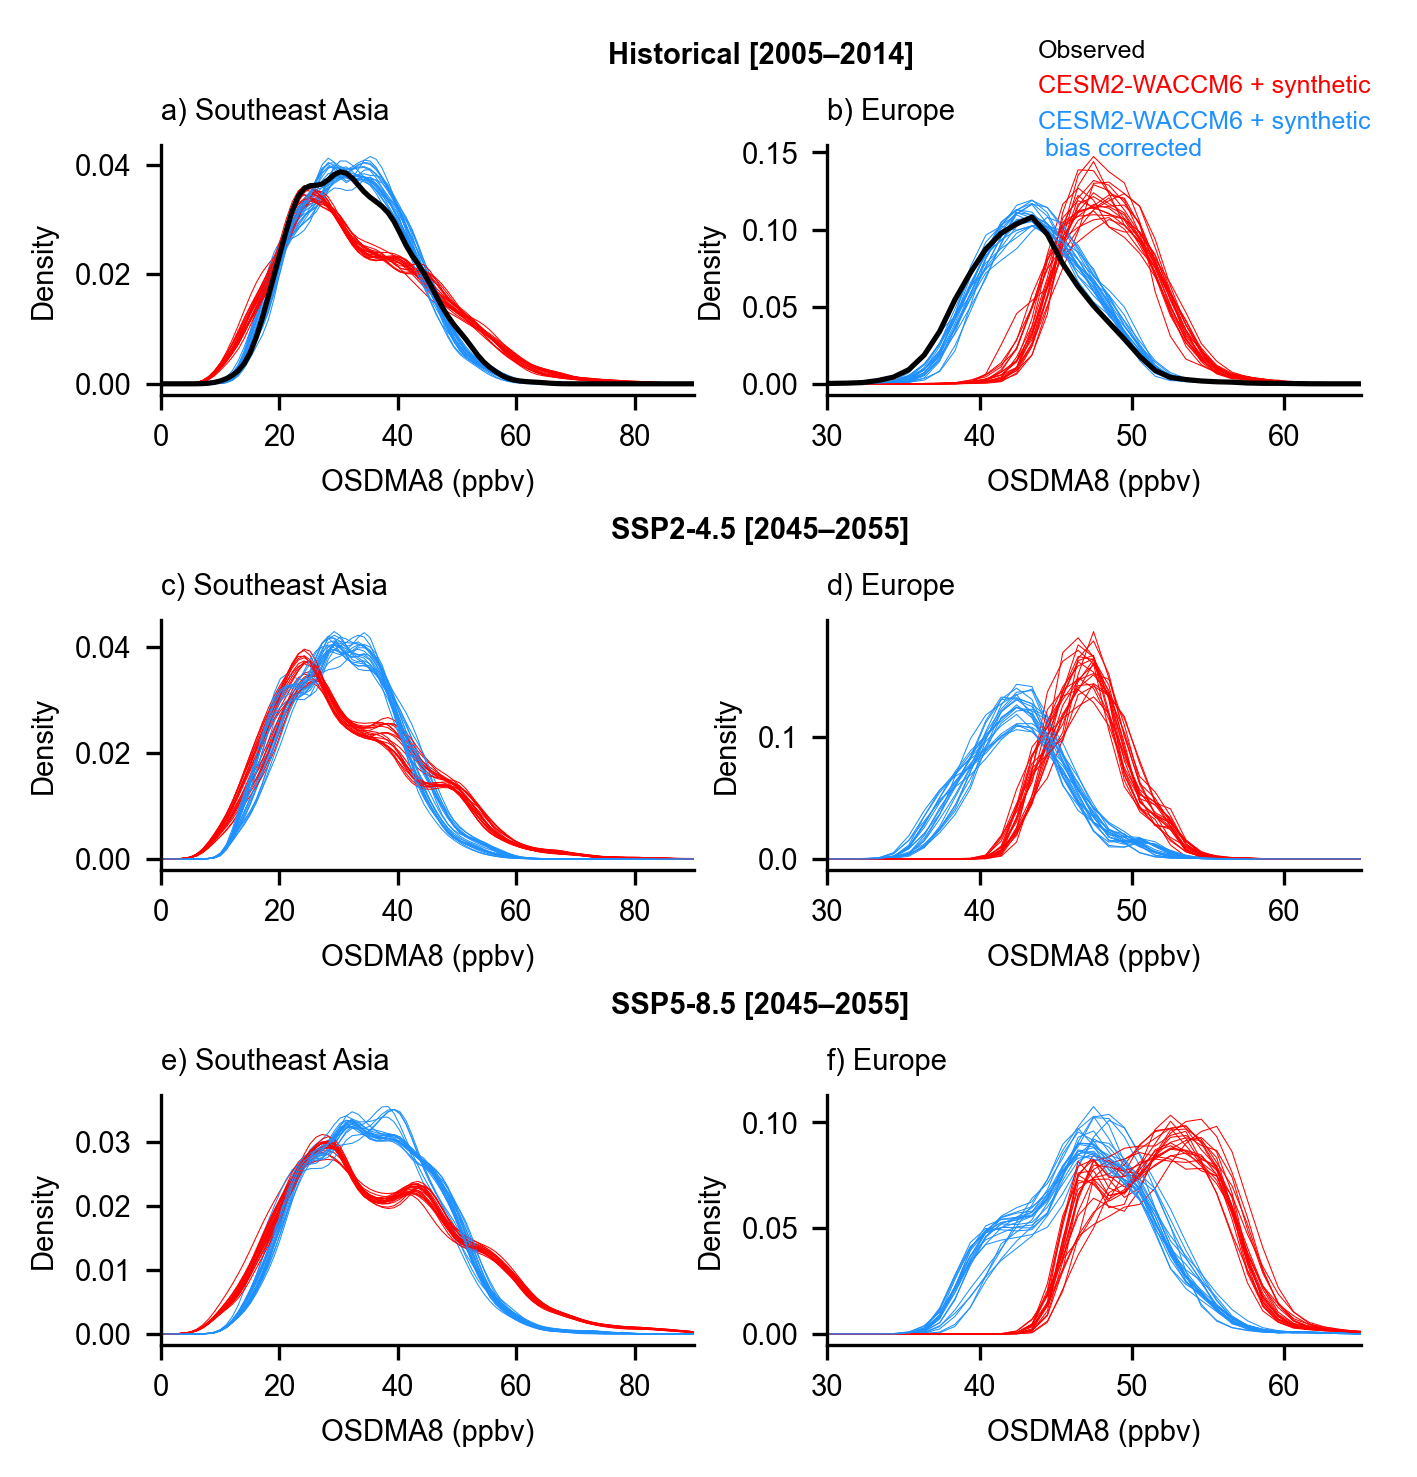

In [27]:
def get_valid_values(member_ds, candidate_vars, min_n=2):
    for var in candidate_vars:
        if var not in member_ds.data_vars:
            continue

        x = np.asarray(member_ds[var].values).ravel()
        x = x[np.isfinite(x)]

        if x.size < min_n:
            continue
        if np.nanstd(x) == 0:
            continue

        return x, var

    return None, None

def plot_kde(values, ax, color, label, lw=1.5):
    x = np.asarray(values).ravel()
    x = x[np.isfinite(x)]

    if x.size < 2:
        return False
    if np.nanstd(x) == 0:
        return False

    xs = np.linspace(0, 100, 100)
    pdf = gaussian_kde(x)
    ax.plot(xs, pdf(xs), linewidth=lw, color=color, label=label)
    return True

def plot_member_group(ds_region, ax):
    added_main_label = False
    added_bc_label = False

    #n_members = ds_region.sizes["ensemble_member"]

    #for member in range(n_members):
    for member in range(20): # don't plot all members --> only use up to 20 total 
        member_ds = ds_region.isel(ensemble_member=member)
        # Main: y_true -> y_pred
        x_main, used_main = get_valid_values(member_ds, ["y_true", "y_pred"])
        if x_main is not None:
            ok = plot_kde(
                x_main,
                ax,
                color="red",
                label="CESM2-WACCM6 + synthetic" if not added_main_label else "_nolegend_",
                lw=0.25,
            )
            if ok:
                added_main_label = True

        # Bias-corrected: y_true_bc -> y_pred_bc
        x_bc, used_bc = get_valid_values(member_ds, ["y_true_bc", "y_pred_bc"])
        if x_bc is not None:
            ok = plot_kde(
                x_bc,
                ax,
                color="dodgerblue",
                label="CESM2-WACCM6 + synthetic \n bias corrected" if not added_bc_label else "_nolegend_",
                lw=0.25,
            )
            if ok:
                added_bc_label = True


utils.set_matplotlib_font("Arial")
fig_width_in = 5
fig_height_in = 5
fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=300)

gs1 = GridSpec(
    3, 2,
    top=0.90, bottom=0.10, left=0.08, right=0.88,
    hspace=0.90, wspace=0.25
)

ax1 = fig.add_subplot(gs1[0, 0])
ax2 = fig.add_subplot(gs1[0, 1])

ax3 = fig.add_subplot(gs1[1, 0])
ax4 = fig.add_subplot(gs1[1, 1])

ax5 = fig.add_subplot(gs1[2, 0])
ax6 = fig.add_subplot(gs1[2, 1])

####### plotting calls ##########

plot_member_group(hist_sea, ax1)
plot_member_group(hist_wce, ax2)

plot_kde(ramp_sea.ozone.values.ravel(), ax1, color="black", label="Observed", lw=1.25)
plot_kde(ramp_wce.ozone.values.ravel(), ax2, color="black", label="Observed", lw=1.25)

plot_member_group(ssp245_sea, ax3)
plot_member_group(ssp245_wce, ax4)

plot_member_group(ssp585_sea, ax5)
plot_member_group(ssp585_wce, ax6)

##################################


ax1.set_title("a) Southeast Asia", loc="left", fontsize=7)
ax2.set_title("b) Europe", loc="left", fontsize=7)

ax3.set_title("c) Southeast Asia", loc="left", fontsize=7)
ax4.set_title("d) Europe", loc="left", fontsize=7)

ax5.set_title("e) Southeast Asia", loc="left", fontsize=7)
ax6.set_title("f) Europe", loc="left", fontsize=7)


for axes in [ax1, ax2, ax3, ax4, ax5, ax6]:
    axes.set_xlabel("OSDMA8 (ppbv)", fontsize=7)
    axes.set_ylabel("Density", fontsize=7)
    axes.tick_params(axis="both", labelsize=7)
    axes.spines["top"].set_visible(False)
    axes.spines["right"].set_visible(False)

for axes in [ax1, ax3, ax5]:  
    axes.set_xlim([0,90])

for axes in [ax2, ax4, ax6]:  
    axes.set_xlim([30, 65])

handles, labels = ax1.get_legend_handles_labels()
handle_map = dict(zip(labels, handles))

legend_labels = [
    lab for lab in [
        "Observed",
        "CESM2-WACCM6 + synthetic",
        "CESM2-WACCM6 + synthetic \n bias corrected",
    ]
    if lab in handle_map
]

fig.legend(
    [handle_map[lab] for lab in legend_labels],
    legend_labels,
    loc="center left",
    bbox_to_anchor=(0.65, 0.93),
    fontsize=6,
    frameon=False,
    handlelength=0,
    handletextpad=0.0,
    labelcolor="linecolor",
)


# centered row titles
row1_left, row1_right = ax1.get_position(), ax2.get_position()
row2_left, row2_right = ax3.get_position(), ax4.get_position()
row3_left, row3_right = ax5.get_position(), ax6.get_position()

x_row1 = 0.5 * (row1_left.x0 + row1_right.x1)
x_row2 = 0.5 * (row2_left.x0 + row2_right.x1)
x_row3 = 0.5 * (row3_left.x0 + row3_right.x1)

y_row1 = row1_left.y1 + 0.05
y_row2 = row2_left.y1 + 0.05
y_row3 = row3_left.y1 + 0.05

fig.text(
    x_row1, y_row1, "Historical [2005–2014]",
    ha="center", va="bottom", fontsize=7, color="black", fontweight='bold'
)

fig.text(
    x_row2, y_row2, "SSP2-4.5 [2045–2055]",
    ha="center", va="bottom", fontsize=7, color="black", fontweight='bold'
)

fig.text(
    x_row3, y_row3, "SSP5-8.5 [2045–2055]",
    ha="center", va="bottom", fontsize=7, color="black", fontweight='bold'
)